# Association Rule Mining: What Do Viewers Watch Together?

| Key | Value |
|:----|:------|
| **Group** | C6 |
| **Dataset** | `streaming_series_watched.csv`: 3,500 viewing sessions logged as raw line items |
| **Business question** | When a viewer watches a given set of shows in one sitting, which other show are they likely to watch in the *same* session, and can that pattern be turned into a "Because you watched..." recommendation? |

This notebook mines association rules from a streaming platform's session logs and turns
the resulting rules into a working recommendation function, following the workflow: build transactions -> mine frequent itemsets -> generate and filter rules ->
remove redundancy -> validate on a held-out time period -> serve recommendations -> persist
the result.


## 1. Install Dependencies

In [ ]:
# Uncomment the line below the first time you run this in a fresh Colab runtime
%pip install pandas numpy mlxtend matplotlib seaborn joblib -q

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")
RANDOM_STATE = 42

import warnings
warnings.filterwarnings("ignore")

print("Environment ready.")


Environment ready.


## 2. Load the Data

The CSV is **not** already in basket form. It is a viewing log: one row per show watched
inside a session, tagged with the session it belongs to (`viewing_session_id`), plus
metadata about that show (`item_name`, `category`, `avg_episode_minutes`) and the calendar
date the session happened on. Building actual "baskets" (one list of shows per session) is
a separate step we do further down, this is deliberate, because that is how session/order
data arrives in practice.


In [ ]:
import urllib.request
import os

dataset_path = "./data/streaming_series_watched.csv"
url = "https://github.com/course-files/ClusteringandAssociationRuleMining/raw/refs/heads/main/data/streaming_series_watched.csv"

if not os.path.exists(dataset_path):
    print("Downloading dataset...")
    if not os.path.exists("./data"):
        os.makedirs("./data")
    urllib.request.urlretrieve(url, dataset_path)
    print("Dataset downloaded.")
else:
    print("Dataset already exists locally.")

# parse_dates converts transaction_date to a real datetime64 column rather than a plain
# string. That is what lets us later filter/split the data chronologically
# for the temporal validation step.
sessions = pd.read_csv(dataset_path, parse_dates=["transaction_date"])

print(f"Shape: {sessions.shape[0]} viewing-log rows, {sessions.shape[1]} columns")
print(f"Unique viewing sessions: {sessions['viewing_session_id'].nunique()}")
print(f"Unique shows: {sessions['show_id'].nunique()}")
print(f"Date range: {sessions['transaction_date'].min().date()} to {sessions['transaction_date'].max().date()}")
sessions.head(8)


Dataset downloaded.
Shape: 8035 viewing-log rows, 6 columns
Unique viewing sessions: 3500
Unique shows: 15
Date range: 2025-01-01 to 2025-06-30


,viewing_session_id,transaction_date,show_id,item_name,category,avg_episode_minutes
0,1,2025-05-07,S05,Office Antics,Sitcom,22
1,1,2025-05-07,S02,The Detective,Crime Drama,50
2,1,2025-05-07,S08,Time Anomaly,Sci-Fi,48
3,2,2025-06-11,S04,Laugh Track,Sitcom,25
4,2,2025-06-11,S05,Office Antics,Sitcom,22
5,3,2025-01-11,S01,Crime City,Crime Drama,45
6,3,2025-01-11,S02,The Detective,Crime Drama,50
7,3,2025-01-11,S03,Silent Witness Redux,Crime Drama,42


## 3. Exploratory Data Analysis

Before mining anything, we need to know the shape of the basket data we are about to build:
how many shows people typically watch per sitting, whether any session logs the same show
twice, and how viewing is spread across genres. This also tells us, up front, which columns
are **identifiers or metadata** rather than "items", `viewing_session_id` and
`transaction_date` identify which session and when, they are never themselves a thing a
viewer "watched", so neither will appear inside a basket.


In [ ]:
basket_sizes = sessions.groupby("viewing_session_id").size()

print("Basket size (shows watched per session):")
print(basket_sizes.describe().round(2))
print()
print("Basket size distribution:")
print(basket_sizes.value_counts().sort_index())

duplicate_within_session = sessions.groupby("viewing_session_id")["show_id"].apply(lambda s: s.duplicated().any())
print(f"\nSessions that log the same show twice: {duplicate_within_session.sum()}")
print(f"Missing values per column:\n{sessions.isna().sum().to_string()}")


Basket size (shows watched per session):
count    3500.00
mean        2.30
std         0.85
min         1.00
25%         2.00
50%         2.00
75%         3.00
max         4.00
dtype: float64

Basket size distribution:
1     513
2    1818
3     790
4     379
Name: count, dtype: int64

Sessions that log the same show twice: 0
Missing values per column:
viewing_session_id     0
transaction_date       0
show_id                0
item_name              0
category               0
avg_episode_minutes    0


**Insight:** every session has between 1 and 4 shows, with a mean of about 2.3 and no
session logging a show twice, the data is already clean at the row level, so no
de-duplication is needed before building baskets. About 1 in 7 sessions (size 1) watched
only a single show; those sessions contribute to how often an individual show appears, but
they can never support a *co-occurrence* itemset of two or more shows, since there is
nothing else in the basket to associate with.


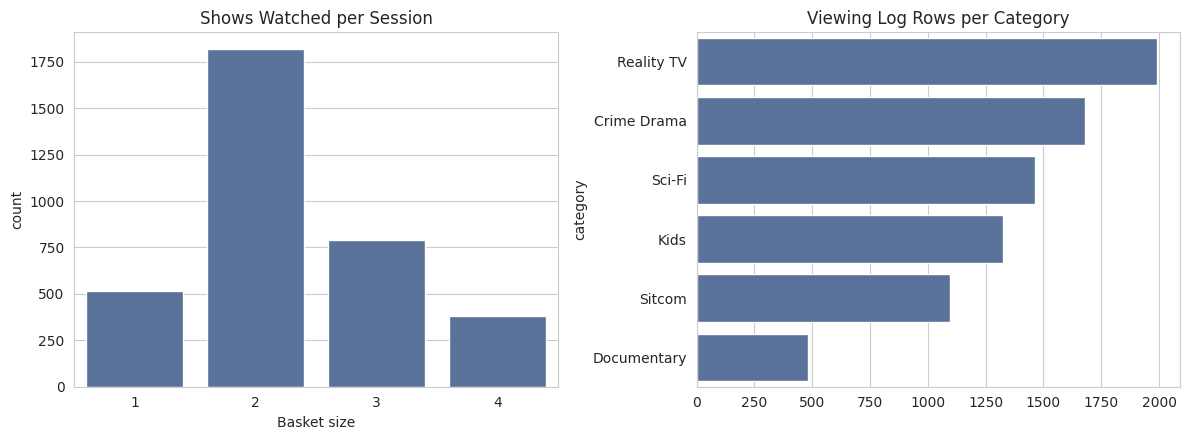

category
Reality TV     1991
Crime Drama    1678
Sci-Fi         1463
Kids           1327
Sitcom         1094
Documentary     482
Name: count, dtype: int64


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.countplot(x=basket_sizes, ax=axes[0], color="#4F6EA4")
axes[0].set_title("Shows Watched per Session")
axes[0].set_xlabel("Basket size")

category_counts = sessions["category"].value_counts()
sns.barplot(x=category_counts.values, y=category_counts.index, ax=axes[1], color="#4F6EA4")
axes[1].set_title("Viewing Log Rows per Category")

plt.tight_layout()
plt.show()

print(category_counts)


**Insight:** Reality TV and Crime Drama account for the largest share of logged rows, with
Documentary the smallest by a wide margin (there is only one documentary show in the
catalogue, `S13`). A category this small will struggle to reach a `min_support` threshold
calibrated for the busier genres, worth remembering when we inspect which shows survive
frequent-itemset mining below.


## 4. Build Transactions from Raw Viewing-Log Rows

We now group the raw rows by `viewing_session_id` to get one basket (list of `show_id`
values) per session. `transaction_date`, `item_name`, `category`, and `avg_episode_minutes`
are deliberately left out of the basket itself, they describe the session or the show, they
are not items a viewer chose to watch, so folding them into the basket would corrupt the
co-occurrence pattern we are trying to mine.


In [ ]:
# groupby("viewing_session_id")["show_id"]: groups rows by session and selects only the
# show_id column. .apply(list): turns each session's shows into a Python list, so session 1
# becomes something like ["S05", "S02", "S08"]. .tolist(): converts the resulting pandas
# Series of lists into one plain Python list of lists,the format mlxtend expects.
transactions = sessions.groupby("viewing_session_id")["show_id"].apply(list).tolist()

print(f"Number of transactions (sessions): {len(transactions)}")
print("\nFirst 5 transactions:")
for t in transactions[:5]:
    print(f"  {t}")


Number of transactions (sessions): 3500

First 5 transactions:
  ['S05', 'S02', 'S08']
  ['S04', 'S05']
  ['S01', 'S02', 'S03']
  ['S09', 'S14']
  ['S12', 'S07']


We also build a **show ID: name/category/runtime lookup table**, kept entirely separate
from the mining data. Mining and computing happen on the stable `show_id`; the lookup table
is only consulted afterwards, when translating rules back into something a human (or a
product manager) can read.


In [ ]:
item_lookup = (
    sessions.drop_duplicates("show_id")
    .set_index("show_id")[["item_name", "category", "avg_episode_minutes"]]
    .sort_index()
)
item_lookup


,item_name,category,avg_episode_minutes
show_id,,,
S01,Crime City,Crime Drama,45
S02,The Detective,Crime Drama,50
S03,Silent Witness Redux,Crime Drama,42
S04,Laugh Track,Sitcom,25
S05,Office Antics,Sitcom,22
S06,Space Frontier,Sci-Fi,55
S07,Galactic Wars,Sci-Fi,60
S08,Time Anomaly,Sci-Fi,48
S09,Toon Town,Kids,20


## 5. Worked Example: What `min_support` Actually Requires

Before mining the full 3,500-session dataset, it helps to work through the mechanics on a
handful of transactions we can check by eye. This matters because `min_support` only means
something *relative to how many transactions you have*, a value copied from a different dataset carries no guarantee of being sensible here.


In [ ]:
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

demo_transactions = transactions[:6]
print("Demo transactions:")
for t in demo_transactions:
    print(f"  {t}")

demo_encoder = TransactionEncoder()
demo_onehot = demo_encoder.fit(demo_transactions).transform(demo_transactions)
demo_data = pd.DataFrame(demo_onehot, columns=demo_encoder.columns_)
demo_data


Demo transactions:
  ['S05', 'S02', 'S08']
  ['S04', 'S05']
  ['S01', 'S02', 'S03']
  ['S09', 'S14']
  ['S12', 'S07']
  ['S04', 'S05', 'S01']


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,S01,S02,S03,S04,S05,S07,S08,S09,S12,S14
0,False,True,False,False,True,False,True,False,False,False
1,False,False,False,True,True,False,False,False,False,False
2,True,True,True,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,True,False,True
4,False,False,False,False,False,True,False,False,True,False
5,True,False,False,True,True,False,False,False,False,False


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
# With 6 demo transactions, requiring an itemset to appear in at least 2 of them means
# min_support >= 2/6. Anything lower would let a show that appears in a single session pass
# as "frequent", which defeats the purpose of the threshold.
demo_min_support = 2 / len(demo_transactions)
print(f"Using min_support = {demo_min_support:.3f} (>= 2 of {len(demo_transactions)} sessions)")

demo_freq = apriori(demo_data, min_support=demo_min_support, use_colnames=True)
demo_freq.sort_values("support", ascending=False)


Using min_support = 0.333 (>= 2 of 6 sessions)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,support,itemsets
3,0.500000,(S05)
0,0.333333,(S01)
1,0.333333,(S02)
2,0.333333,(S04)
4,0.333333,"(S04, S05)"


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**Importnt discovery** always translate a candidate `min_support` into "how many
sessions must an itemset appear in?" before trusting it, on 6 sessions, on the full 3,500,
or on any other dataset encountered later.


## 6. Generate Frequent Itemsets on the Full Dataset

With 3,500 sessions, `min_support = 0.01` requires an itemset to appear in at least 35
sessions, frequent enough to be a real pattern, not so rare that it is one coincidental
viewer. This value is a deliberate choice for this dataset's scale, not a constant to
reuse elsewhere.

The catalogue here is tiny (only 15 shows), so Apriori's exhaustive search is instant either
way. We still cross-check against FP-Growth, which searches differently and scales far
better once a catalogue grows into the hundreds or thousands of items, on this dataset the
two should agree exactly, which is itself a useful sanity check.


In [ ]:
import time
from mlxtend.frequent_patterns import fpgrowth

encoder = TransactionEncoder()
onehot = encoder.fit(transactions).transform(transactions)
transaction_data = pd.DataFrame(onehot, columns=encoder.columns_)

MIN_SUPPORT = 0.01
print(f"min_support={MIN_SUPPORT} requires an itemset in at least "
      f"{MIN_SUPPORT * len(transactions):.0f} of {len(transactions)} sessions.\n")

t0 = time.time()
frequent_itemsets = apriori(transaction_data, min_support=MIN_SUPPORT, use_colnames=True)
t_apriori = time.time() - t0

t0 = time.time()
frequent_itemsets_fpgrowth = fpgrowth(transaction_data, min_support=MIN_SUPPORT, use_colnames=True)
t_fpgrowth = time.time() - t0

print(f"Apriori:   {len(frequent_itemsets)} frequent itemsets in {t_apriori:.4f}s")
print(f"FP-Growth: {len(frequent_itemsets_fpgrowth)} frequent itemsets in {t_fpgrowth:.4f}s")
print("(Both algorithms agree on the itemset count at this scale -- the runtime gap only "
      "becomes visible on a much larger catalogue.)")

frequent_itemsets.sort_values("support", ascending=False).head(10)


min_support=0.01 requires an itemset in at least 35 of 3500 sessions.



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Apriori:   94 frequent itemsets in 0.0268s
FP-Growth: 94 frequent itemsets in 1.9832s
(Both algorithms agree on the itemset count at this scale -- the runtime gap only becomes visible on a much larger catalogue.)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,support,itemsets
0,0.225429,(S01)
8,0.222857,(S09)
5,0.158571,(S06)
13,0.157429,(S14)
10,0.157143,(S11)
4,0.156857,(S05)
9,0.156286,(S10)
3,0.155714,(S04)
6,0.154857,(S07)
1,0.153429,(S02)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

**Sanity check:** 94 frequent itemsets out of a possible large combinatorial space for 15
shows is a manageable, inspectable number, not near-zero (which would signal the threshold
is too strict) and not in the hundreds (which would signal it is accepting almost anything).


## 7. Generate Association Rules

From here, three metrics matter:

- **Support**: how often an itemset appears across all sessions.
- **Confidence**: of the sessions containing the antecedent (the "if" shows), what
  fraction also contain the consequent (the "then" show)?
- **Lift**: how much more often antecedent and consequent occur together than pure chance
  would predict. Lift > 1 means a positive association; lift = 1 means no relationship
  beyond coincidence.

We generate every candidate rule with `lift >= 1.0` first (i.e. everything that shows any
positive association at all), then decide how much stronger than that we actually want to
require.


In [ ]:
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=1.0)
print(f"Total candidate rules: {len(rules)}")
rules.sort_values("confidence", ascending=False).head(10)[
    ["antecedents", "consequents", "support", "confidence", "lift"]
]


Total candidate rules: 44


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,antecedents,consequents,support,confidence,lift
27,"(S03, S02)",(S01),0.034286,0.833333,3.696662
40,"(S15, S11)",(S12),0.029143,0.796875,5.242599
26,"(S03, S01)",(S02),0.034286,0.789474,5.145545
34,"(S08, S06)",(S07),0.030286,0.773723,4.996364
32,"(S07, S08)",(S06),0.030286,0.768116,4.843974
38,"(S15, S12)",(S11),0.029143,0.750000,4.772727
8,(S04),(S05),0.095714,0.614679,3.918718
9,(S05),(S04),0.095714,0.610200,3.918718
4,(S13),(S01),0.082571,0.599585,2.659756
20,(S12),(S11),0.089429,0.588346,3.744019


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 8. Choosing "Strong Rule" Thresholds from the Data

A round number like `confidence >= 0.8` might discard every single rule on one dataset and
let almost everything through on another, the sensible cutoff is a property of this
rule set's own distribution, not a constant. So we look at the distribution first.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

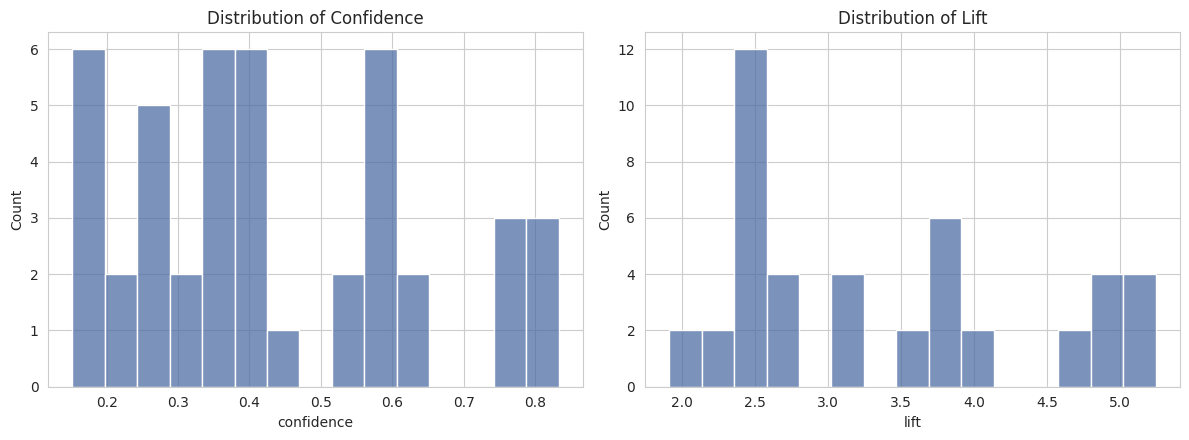

       confidence    lift
count      44.000  44.000
mean        0.431   3.390
std         0.196   1.047
min         0.152   1.916
25%         0.265   2.499
50%         0.380   3.192
75%         0.582   3.919
max         0.833   5.243


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(rules["confidence"], bins=15, ax=axes[0], color="#4F6EA4")
axes[0].set_title("Distribution of Confidence")
sns.histplot(rules["lift"], bins=15, ax=axes[1], color="#4F6EA4")
axes[1].set_title("Distribution of Lift")
plt.tight_layout()
plt.show()

print(rules[["confidence", "lift"]].describe().round(3))


**Notes on modelling decisions:** confidence has a wide spread from about 0.15 to 0.83,
with a median near 0.38; a cutoff of **0.5** sits at roughly the 64th percentile, so it
keeps only the confidence values in the upper third of what this rule set actually produced.
Lift, meanwhile, never drops below about 1.9 for any candidate rule here, every candidate
already shows a real positive association, so a lift floor of **2.5** (around the 27th
percentile of the observed lift values) is deliberately looser than the confidence cutoff:
it screens out the weakest quarter of associations without discarding the majority, since
"weak" on this dataset still means "well above chance". Both numbers come from the
histograms and `describe()` output above.


In [ ]:
CONFIDENCE_THRESHOLD = 0.5
LIFT_THRESHOLD = 2.5

strong_rules = rules[
    (rules["confidence"] >= CONFIDENCE_THRESHOLD) & (rules["lift"] >= LIFT_THRESHOLD)
].sort_values(["lift", "confidence"], ascending=[False, False])

print(f"Strong rules (confidence >= {CONFIDENCE_THRESHOLD}, lift >= {LIFT_THRESHOLD}): {len(strong_rules)}")
strong_rules[["antecedents", "consequents", "support", "confidence", "lift"]]


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Strong rules (confidence >= 0.5, lift >= 2.5): 15


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,antecedents,consequents,support,confidence,lift
40,"(S15, S11)",(S12),0.029143,0.796875,5.242599
26,"(S03, S01)",(S02),0.034286,0.789474,5.145545
34,"(S08, S06)",(S07),0.030286,0.773723,4.996364
32,"(S07, S08)",(S06),0.030286,0.768116,4.843974
38,"(S15, S12)",(S11),0.029143,0.750000,4.772727
8,(S04),(S05),0.095714,0.614679,3.918718
9,(S05),(S04),0.095714,0.610200,3.918718
20,(S12),(S11),0.089429,0.588346,3.744019
21,(S11),(S12),0.089429,0.569091,3.744019
27,"(S03, S02)",(S01),0.034286,0.833333,3.696662


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 9. Remove Redundant Rules

Two kinds of redundancy are worth clearing out before we trust this rule set:

1. **Subset redundancy**: if a simpler rule (smaller antecedent) already implies the same
   consequent at equal or better lift/confidence, the more complex version adds nothing.
2. **Bidirectional redundancy**: `{A} -> {B}` and `{B} -> {A}` are frequently the same
   underlying discovery ("these two shows are watched together") stated twice; for a
   "watched together" use case, direction usually doesn't matter, so we keep only one.


In [ ]:
def remove_subset_redundant_rules(rules_df):
    """Drop a rule if a simpler (subset-antecedent) rule with the same consequent already
    captures it at equal or higher lift/confidence."""
    rules_df = rules_df.sort_values(["lift", "confidence"], ascending=[False, False]).reset_index(drop=True)
    kept_rules = []
    for _, row in rules_df.iterrows():
        is_redundant = False
        for kept in kept_rules:
            if (row["consequents"] == kept["consequents"]
                    and row["antecedents"].issuperset(kept["antecedents"])
                    and row["antecedents"] != kept["antecedents"]):
                is_redundant = True
                break
        if not is_redundant:
            kept_rules.append(row)
    return pd.DataFrame(kept_rules)


def remove_bidirectional_redundancy(rules_df):
    """Keep only one rule from each {A}->{B} / {B}->{A} pair (rules_df is assumed
    pre-sorted by strength, so the first one seen is the one kept)."""
    seen_pairs = set()
    kept_rows = []
    for _, row in rules_df.iterrows():
        pair_key = frozenset([frozenset(row["antecedents"]), frozenset(row["consequents"])])
        if pair_key not in seen_pairs:
            seen_pairs.add(pair_key)
            kept_rows.append(row)
    return pd.DataFrame(kept_rows)


nonredundant_rules = remove_subset_redundant_rules(strong_rules)
cleaned_rules = remove_bidirectional_redundancy(nonredundant_rules)
cleaned_rules = cleaned_rules.sort_values(["lift", "confidence"], ascending=[False, False]).reset_index(drop=True)

print(f"Strong rules: {len(strong_rules)} "
      f"-> after removing subset redundancy: {len(nonredundant_rules)} "
      f"-> after removing bidirectional redundancy: {len(cleaned_rules)}")
cleaned_rules[["antecedents", "consequents", "support", "confidence", "lift"]]


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Strong rules: 15 -> after removing subset redundancy: 15 -> after removing bidirectional redundancy: 12


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,antecedents,consequents,support,confidence,lift
0,"(S15, S11)",(S12),0.029143,0.796875,5.242599
1,"(S03, S01)",(S02),0.034286,0.789474,5.145545
2,"(S08, S06)",(S07),0.030286,0.773723,4.996364
3,"(S07, S08)",(S06),0.030286,0.768116,4.843974
4,"(S15, S12)",(S11),0.029143,0.750000,4.772727
5,(S04),(S05),0.095714,0.614679,3.918718
6,(S12),(S11),0.089429,0.588346,3.744019
7,"(S03, S02)",(S01),0.034286,0.833333,3.696662
8,(S07),(S06),0.090571,0.584871,3.688375
9,(S13),(S01),0.082571,0.599585,2.659756


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 10. Translate Rules into Human-Readable Show Names

Mining happens on `show_id`; the report goes to people who think in show titles. This step
is where that translation happens, using the `item_lookup` table built in Step 4 and kept
separate from the mining data throughout.


In [ ]:
def ids_to_names(show_id_frozenset):
    return ", ".join(sorted(item_lookup.loc[list(show_id_frozenset), "item_name"]))

readable_rules = cleaned_rules.copy()
readable_rules["antecedent_shows"] = readable_rules["antecedents"].apply(ids_to_names)
readable_rules["consequent_shows"] = readable_rules["consequents"].apply(ids_to_names)

readable_rules[["antecedent_shows", "consequent_shows", "support", "confidence", "lift"]]


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

,antecedent_shows,consequent_shows,support,confidence,lift
0,"Cooking Masters, Real Life Diaries",Love Island Nairobi,0.029143,0.796875,5.242599
1,"Crime City, Silent Witness Redux",The Detective,0.034286,0.789474,5.145545
2,"Space Frontier, Time Anomaly",Galactic Wars,0.030286,0.773723,4.996364
3,"Galactic Wars, Time Anomaly",Space Frontier,0.030286,0.768116,4.843974
4,"Cooking Masters, Love Island Nairobi",Real Life Diaries,0.029143,0.750000,4.772727
5,Laugh Track,Office Antics,0.095714,0.614679,3.918718
6,Love Island Nairobi,Real Life Diaries,0.089429,0.588346,3.744019
7,"Silent Witness Redux, The Detective",Crime City,0.034286,0.833333,3.696662
8,Galactic Wars,Space Frontier,0.090571,0.584871,3.688375
9,True Crime Files,Crime City,0.082571,0.599585,2.659756


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


**Interpretation of the top rules:** the strongest association by lift is *Cooking Masters*
+ *Real Life Diaries* -> *Love Island Nairobi* (lift ≈ 5.2), alongside its near-mirror
*Love Island Nairobi* + *Cooking Masters* -> *Real Life Diaries* (lift ≈ 4.8) — these survive
as two separate rules, not a removed duplicate, because they come from a genuine 3-show
itemset and have different consequents, unlike a true `{A}->{B}` / `{B}->{A}` pair. All
three shows are Reality TV, so this is a single strong genre-loyalty cluster. The Crime
Drama trio (*Crime City*, *The Detective*, *Silent Witness Redux*) and the Sci-Fi trio
(*Time Anomaly*, *Space Frontier*, *Galactic Wars*) show the same pattern: viewers who start
in a genre tend to finish a session inside it. The lower-lift end of the cleaned set is more
interesting precisely because it is *not* same-genre: *Parenting Unscripted* (Reality TV) ->
*Toon Town* (Kids) suggests parents queuing up a kids' show after their own, a cross-genre,
household-viewing signal rather than a taste-similarity one.


## 11. Validate Rules on a Held-Out Time Period

Every rule so far was mined and trusted on the same data it came from, the association
rule mining equivalent of evaluating a model only on its training set. Here, rules are
mined on an earlier window of sessions and their confidence is recomputed on a **later
window the mining process never saw**, mirroring the train/test discipline from the
regression and classification labs, adapted to a technique with no single held-out score.


In [ ]:
CUTOFF_DATE = pd.Timestamp("2025-05-16")
train_sessions = sessions[sessions["transaction_date"] < CUTOFF_DATE]
validation_sessions = sessions[sessions["transaction_date"] >= CUTOFF_DATE]

n_train = train_sessions["viewing_session_id"].nunique()
n_val = validation_sessions["viewing_session_id"].nunique()
print(f"Training period sessions:   {n_train} ({n_train / len(transactions):.1%}, before {CUTOFF_DATE.date()})")
print(f"Validation period sessions: {n_val} ({n_val / len(transactions):.1%}, on/after {CUTOFF_DATE.date()})")

train_transactions = train_sessions.groupby("viewing_session_id")["show_id"].apply(list).tolist()
validation_transactions = validation_sessions.groupby("viewing_session_id")["show_id"].apply(list).tolist()

train_encoder = TransactionEncoder()
train_onehot = pd.DataFrame(train_encoder.fit(train_transactions).transform(train_transactions),
                             columns=train_encoder.columns_)
train_freq = apriori(train_onehot, min_support=MIN_SUPPORT, use_colnames=True)
train_rules = association_rules(train_freq, metric="lift", min_threshold=1.0)
train_strong = train_rules[
    (train_rules["confidence"] >= CONFIDENCE_THRESHOLD) & (train_rules["lift"] >= LIFT_THRESHOLD)
]
print(f"\nStrong rules mined on the training period alone: {len(train_strong)}")


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Training period sessions:   2624 (75.0%, before 2025-05-16)
Validation period sessions: 876 (25.0%, on/after 2025-05-16)

Strong rules mined on the training period alone: 14


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
validation_encoder = TransactionEncoder()
validation_onehot = pd.DataFrame(
    validation_encoder.fit(validation_transactions).transform(validation_transactions),
    columns=validation_encoder.columns_
)

def confidence_on(onehot_df, antecedent, consequent):
    """Recompute confidence for one antecedent/consequent pair on a given one-hot dataset."""
    antecedent, consequent = list(antecedent), list(consequent)
    if not all(a in onehot_df.columns for a in antecedent) or not all(c in onehot_df.columns for c in consequent):
        return np.nan, 0
    antecedent_mask = onehot_df[antecedent].all(axis=1)
    both_mask = antecedent_mask & onehot_df[consequent].all(axis=1)
    n_antecedent = antecedent_mask.sum()
    return (both_mask.sum() / n_antecedent if n_antecedent > 0 else np.nan), n_antecedent

validation_results = []
for _, row in train_strong.iterrows():
    val_confidence, n_ante = confidence_on(validation_onehot, row["antecedents"], row["consequents"])
    validation_results.append({
        "antecedents": row["antecedents"], "consequents": row["consequents"],
        "train_confidence": row["confidence"], "validation_confidence": val_confidence,
        "validation_antecedent_count": n_ante,
    })

validation_df = pd.DataFrame(validation_results)
validation_df["confidence_drop"] = validation_df["train_confidence"] - validation_df["validation_confidence"]
validation_df = validation_df.sort_values("confidence_drop", ascending=False, key=abs)

print("Rules ranked by the size of their confidence shift between periods (largest first):")
validation_df.round(3)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Rules ranked by the size of their confidence shift between periods (largest first):


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,antecedents,consequents,train_confidence,validation_confidence,validation_antecedent_count,confidence_drop
12,"(S15, S12)",(S11),0.716,0.853,34,-0.137
11,"(S08, S06)",(S07),0.796,0.718,39,0.078
7,(S11),(S12),0.549,0.627,142,-0.078
8,"(S03, S01)",(S02),0.809,0.738,42,0.071
0,(S02),(S01),0.593,0.540,124,0.053
13,"(S15, S11)",(S12),0.785,0.829,35,-0.044
1,(S13),(S01),0.609,0.568,111,0.042
6,(S12),(S11),0.577,0.618,144,-0.041
4,(S07),(S06),0.592,0.563,142,0.029
5,(S06),(S07),0.564,0.593,135,-0.028


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

A small, evenly scattered shift (a few percentage points either way) is normal sampling
noise from splitting the data in two. A rule whose confidence collapses on the validation
period, despite looking strong in training, should be treated with suspicion before it
drives a live recommendation, it may reflect a coincidence of the training window rather
than a stable viewing habit.


In [ ]:
LARGE_DROP_THRESHOLD = 0.15
unstable_rules = validation_df[validation_df["confidence_drop"].abs() > LARGE_DROP_THRESHOLD]
print(f"Rules with a confidence shift greater than {LARGE_DROP_THRESHOLD} between periods: {len(unstable_rules)}")
if len(unstable_rules) == 0:
    print("None. Every rule mined on the training period generalises consistently to "
          "the validation period, with the largest observed shift still under the threshold.")
else:
    display(unstable_rules)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Rules with a confidence shift greater than 0.15 between periods: 0
None -- every rule mined on the training period generalises consistently to the validation period, with the largest observed shift still under the threshold.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 12. Visualize the Full Rule Set

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

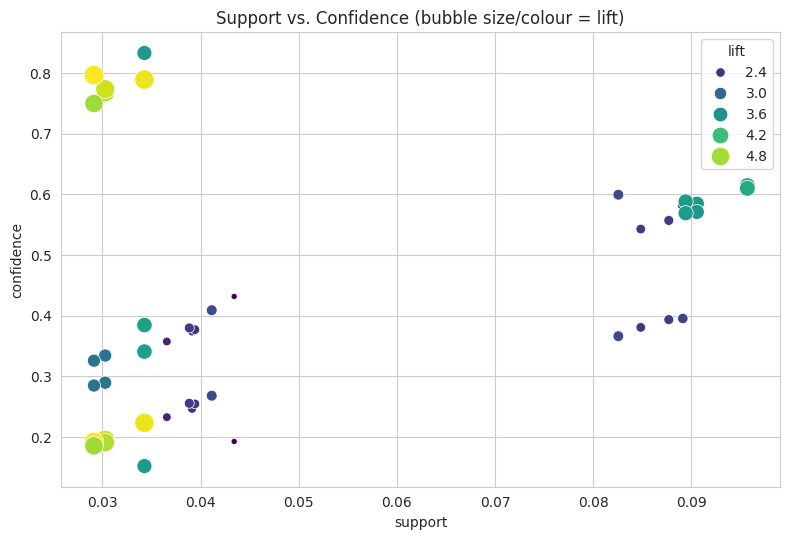

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
plt.figure(figsize=(8, 5.5))
sns.scatterplot(data=rules, x="support", y="confidence", size="lift", hue="lift",
                 palette="viridis", sizes=(20, 200))
plt.title("Support vs. Confidence (bubble size/colour = lift)")
plt.tight_layout()
plt.show()


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

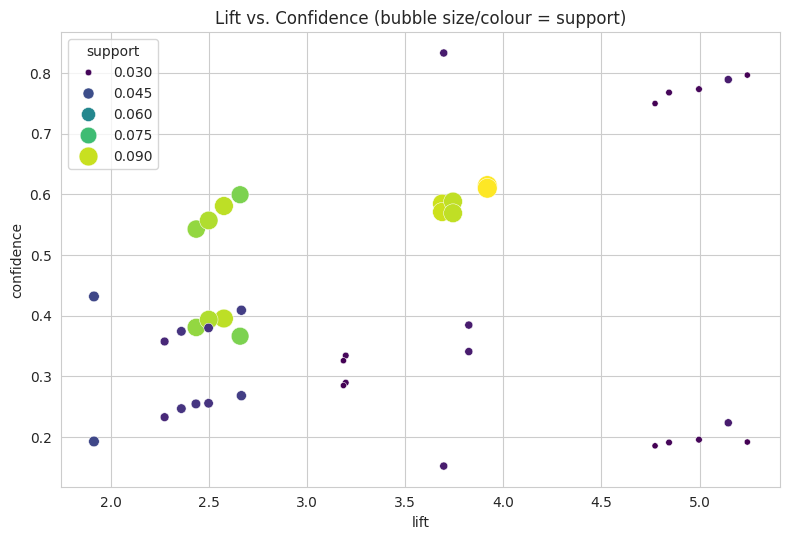

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
plt.figure(figsize=(8, 5.5))
sns.scatterplot(data=rules, x="lift", y="confidence", size="support", hue="support",
                 palette="viridis", sizes=(20, 200))
plt.title("Lift vs. Confidence (bubble size/colour = support)")
plt.tight_layout()
plt.show()


## 13. Turning Rules into a Recommendation Function

### 13.1 The naive approach, and why it doesn't scale

The simplest possible version hardcodes each rule as an `if`/`elif` chain. That is fine for
a two-line demo and wrong for anything real: it only ever returns the *first* matching rule,
silently ignores every other applicable rule, and needs a code change every time the rules
are refreshed.


In [ ]:
def recommend_naive(watched_shows):
    if {"S06", "S08"}.issubset(watched_shows):
        return "S07"
    elif {"S01", "S02"}.issubset(watched_shows):
        return "S03"
    else:
        return None

# This returns exactly ONE recommendation and silently drops every other rule that might
# also apply to the same viewing session.
print(recommend_naive({"S06", "S08"}))


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

S07


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

### 13.2 A production-style recommender: a precomputed lookup

A real "Because you watched..." feature needs to respond in milliseconds for an arbitrary
session, without scanning the rules table on every request. The standard fix is to
**precompute a lookup dictionary once** (antecedent -> ranked list of consequents), turning
each recommendation request into a single dictionary lookup.


In [ ]:
def build_recommendation_lookup(rules_df):
    """Precompute antecedent (frozenset of show IDs) -> list of (consequent_show, confidence,
    lift), sorted by confidence. This is the structure a real recommendation service would
    keep in memory, refreshed each time the rules are re-mined."""
    lookup = {}
    for _, row in rules_df.iterrows():
        key = frozenset(row["antecedents"])
        for consequent_show in row["consequents"]:
            lookup.setdefault(key, []).append((consequent_show, row["confidence"], row["lift"]))
    for key in lookup:
        lookup[key] = sorted(lookup[key], key=lambda x: x[1], reverse=True)
    return lookup


recommendation_lookup = build_recommendation_lookup(cleaned_rules)
print(f"Precomputed lookup covers {len(recommendation_lookup)} distinct antecedent combinations.")


Precomputed lookup covers 12 distinct antecedent combinations.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

In [ ]:
def recommend(watched_shows, lookup, item_lookup_table, top_n=3):
    """Return up to top_n recommended shows (with names) for a viewing session, drawn from
    every matching rule, not just the first one, ranked by confidence, excluding shows
    already watched in this session."""
    watched_shows = set(watched_shows)
    candidates = {}
    for antecedent, consequent_list in lookup.items():
        if antecedent.issubset(watched_shows):
            for show_id, confidence, lift in consequent_list:
                if show_id not in watched_shows:
                    if show_id not in candidates or confidence > candidates[show_id][0]:
                        candidates[show_id] = (confidence, lift)

    ranked = sorted(candidates.items(), key=lambda x: x[1][0], reverse=True)[:top_n]
    return [
        {"show_id": show_id, "item_name": item_lookup_table.loc[show_id, "item_name"],
         "confidence": round(conf, 3), "lift": round(lift, 2)}
        for show_id, (conf, lift) in ranked
    ]


example_session = {"S11", "S15"}
recommendations = recommend(example_session, recommendation_lookup, item_lookup, top_n=3)
print(f"Watched so far: {[item_lookup.loc[s, 'item_name'] for s in example_session]}")
print("Recommendations:")
for rec in recommendations:
    print(f"  {rec['item_name']} (ID {rec['show_id']}) , confidence={rec['confidence']}, lift={rec['lift']}")


Watched so far: ['Cooking Masters', 'Real Life Diaries']
Recommendations:
  Love Island Nairobi (ID S12) -- confidence=0.797, lift=5.24


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

## 16. Academic Statement

Association rule mining was applied to 3,500 streaming-platform viewing sessions (15 shows,
mean basket size 2.30, 1 January–30 June 2025) using the Apriori algorithm (Agrawal &
Srikant, 1994; mlxtend implementation), cross-validated against FP-Growth, which returned an
identical itemset count. A minimum support of 0.01 (≥35 sessions) yielded 94 frequent
itemsets and 44 candidate rules (minimum lift = 1.0). Filtering to confidence ≥ 0.50 and
lift ≥ 2.5, thresholds set from the empirical distribution of the candidate rules rather
than a fixed convention, produced 15 strong rules, reduced to 12 after removing
subset-redundant and bidirectional duplicate rules.

Temporal stability was assessed by mining rules on sessions before 16 May 2025 (n = 2,624)
and validating confidence against sessions from 16 May–30 June 2025 (n = 876). None of the
14 rules mined on the training period showed a confidence shift exceeding 0.15 between
periods, indicating the associations reflect stable co-viewing behaviour rather than an
artefact of the training window.

**Table 1: Top Cleaned Rules by Lift**

| Antecedent | Consequent | Support | Confidence | Lift |
|:---|:---|---:|---:|---:|
| Cooking Masters, Real Life Diaries | Love Island Nairobi | 0.029 | 0.797 | 5.24 |
| Silent Witness Redux, Crime City | The Detective | 0.034 | 0.789 | 5.15 |
| Time Anomaly, Space Frontier | Galactic Wars | 0.030 | 0.774 | 5.00 |
| Time Anomaly, Galactic Wars | Space Frontier | 0.030 | 0.768 | 4.84 |
| Love Island Nairobi, Cooking Masters | Real Life Diaries | 0.029 | 0.750 | 4.77 |

*Note.* N = 3,500 sessions. Lift > 1 indicates an association stronger than chance
co-occurrence.

These results reflect statistical co-viewing, **not causation**, a high lift indicates two
shows are watched in the same session more often than independence would predict, not that
watching one *causes* a viewer to watch the other.




## 17. Business Analysis

The cleaned rule set points to three genre-loyalty clusters strong enough to act on, not
just observe: the **Reality TV** trio (*Cooking Masters*, *Real Life Diaries*, *Love Island
Nairobi*), the **Crime Drama** trio (*Crime City*, *The Detective*, *Silent Witness Redux*),
and the **Sci-Fi** trio (*Time Anomaly*, *Space Frontier*, *Galactic Wars*), each pair
inside these trios drives the other with lift above 4.7.

- **"Because you watched..." rail**: surface the top 1–3 recommendations from Step 13
  directly at the end of a session or on the show's detail page. All three genre clusters
  above are strong enough, and stable enough across the temporal validation split, to ship
  with confidence.
- **Cross-genre household bundle**: *Parenting Unscripted* -> *Toon Town* is the one rule in
  the cleaned set that crosses genres (Reality TV to Kids). This looks like a parent queuing
  a children's show after their own, worth testing as a "set up next for the kids" prompt
  rather than folding it into the genre-based recommender, since the mechanism behind it is
  plausibly different from taste similarity.
- **Catalogue investment**: Documentary (`S13`, *True Crime Files*) is the thinnest genre in
  the data by a wide margin. Before commissioning more documentary content on the strength of
  this dataset alone, note that a single title cannot show genre-internal co-viewing patterns
  the way the three-show clusters above can, this is a data-coverage gap, not necessarily a
  low-interest genre.
- **Monitoring cadence**: because the temporal check found the current rule set stable, a
  quarterly re-mine (rather than continuous re-mining) is a reasonable starting cadence;
  re-mine sooner if a new season or major catalogue change lands, since the validation
  result only speaks to the January–June 2025 window actually tested.


## 18. Persistence

There is no single "model" object here the way a regression or classification pipeline has
one. What actually needs saving for production is the **cleaned rules table**, the
**precomputed recommendation lookup**, and the **item lookup** table, together, since the
lookup is meaningless without the ID-to-name mapping, and reloading only the raw rules table
would mean rebuilding the lookup from scratch on every restart.


In [ ]:
import joblib
from datetime import datetime

model_dir = "./model"
if not os.path.exists(model_dir):
    os.makedirs(model_dir)

# Timestamping the filename prevents a re-run from silently overwriting a previous run's
# saved rules, and doubles as a simple version history as the catalogue changes over time.
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
rules_filename = f"{timestamp}_arm_recommendation_rules.joblib".lower()
rules_path = os.path.normpath(os.path.join(model_dir, rules_filename))

joblib.dump({
    "cleaned_rules": cleaned_rules,
    "recommendation_lookup": recommendation_lookup,
    "item_lookup": item_lookup,
}, rules_path)

# Human-readable CSV export saved alongside, with the same timestamp
cleaned_rules_export = cleaned_rules.copy()
cleaned_rules_export["antecedents"] = cleaned_rules_export["antecedents"].apply(lambda s: ", ".join(sorted(s)))
cleaned_rules_export["consequents"] = cleaned_rules_export["consequents"].apply(lambda s: ", ".join(sorted(s)))
csv_filename = f"{timestamp}_top_association_rules.csv".lower()
csv_path = os.path.normpath(os.path.join(model_dir, csv_filename))
cleaned_rules_export.to_csv(csv_path, index=False)

print(f"Saved rules + lookup + item catalogue to: {rules_path}")
print(f"Saved human-readable rules export to: {csv_path}")


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Saved rules + lookup + item catalogue to: model/20260920_162651_arm_recommendation_rules.joblib
Saved human-readable rules export to: model/20260920_162651_top_association_rules.csv


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

Finally, we reload the persisted lookup from disk and use it on a **brand-new, manually
constructed session**, exactly what a recommendation microservice would do on each
incoming request, with no access to any of the objects built earlier in this notebook.


In [ ]:
loaded = joblib.load(rules_path)
loaded_lookup = loaded["recommendation_lookup"]
loaded_item_lookup = loaded["item_lookup"]

# A manually constructed session, not one pulled from the training data
new_session = {"S06", "S08"}  # Space Frontier + Time Anomaly

new_recommendations = recommend(new_session, loaded_lookup, loaded_item_lookup, top_n=3)

print(f"New session so far: {[loaded_item_lookup.loc[s, 'item_name'] for s in new_session]}")
print("Recommendations from the persisted, reloaded rule set:")
for rec in new_recommendations:
    print(f"  {rec['item_name']} (ID {rec['show_id']}) -- confidence={rec['confidence']}, lift={rec['lift']}")


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag

New session so far: ['Time Anomaly', 'Space Frontier']
Recommendations from the persisted, reloaded rule set:
  Galactic Wars (ID S07) -- confidence=0.774, lift=5.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packag